# CtreeX experiments

This notebook executes `experiments.py`, which runs the toy example,
comparison of closest counterfactual points with CtreeX's regions and
comparison of PyXAI's formal explanations with CtreeX;
it shows the results of the latter two experiments for trees of depth 4, 6, 8
and 12.
The output LaTeX table only reports the results for the depth-12 trees.
To run this notebook, first install its dependencies with
`uv sync --group experiments --group notebooks` (Python 3.11 or newer) and
then open it with `uv run jupyter lab ./`.

In [1]:
import pandas as pd

import experiments as ex

pd.set_option('display.precision', 2)

In [2]:
print(ex.toy_example())

== Alice {'income': 25, 'age': 22, 'job': 'student'} -> $\ell_3$ decline
The prediction is decline.
Had income been at least 31 (instead of 25), the prediction would have been accept.
Had job been employed or self-employed (instead of student) and age been at least 26 (instead of 22), the prediction would have been accept.
Had job been self-employed (instead of student) and income been at least 51 (instead of 25), the prediction would have been accept.
-- supportive
The prediction is decline since job is student and income is at most 30, whatever the other features.
The prediction is decline since age is at most 25 and income is at most 30, whatever the other features.
-- invariance ranges
job: ['student', 'employed', 'self-employed']
age: ['any value']
income: ['at most 30']
-- contextualised
Had income been at least 31 (instead of 25), the prediction would have been accept, provided that job is student and age is at most 25.
Had job been employed or self-employed (instead of student)

In [3]:
frames = ex.run()

German Credit depth 4: 15 leaves, score 0.620
German Credit depth 6: 34 leaves, score 0.618
German Credit depth 8: 44 leaves, score 0.619
German Credit depth 12: 52 leaves, score 0.671
Adult depth 4: 15 leaves, score 0.701
Adult depth 6: 39 leaves, score 0.764
Adult depth 8: 88 leaves, score 0.764
Adult depth 12: 356 leaves, score 0.764
FICO HELOC depth 4: 15 leaves, score 0.651
FICO HELOC depth 6: 44 leaves, score 0.662
FICO HELOC depth 8: 73 leaves, score 0.601
FICO HELOC depth 12: 115 leaves, score 0.583
California Housing depth 4: 16 leaves, score 0.542
California Housing depth 6: 60 leaves, score 0.622
California Housing depth 8: 198 leaves, score 0.671
California Housing depth 12: 807 leaves, score 0.717


## Trees

Balanced accuracy for the classification data sets and R² for California Housing.

In [4]:
frames['models']

,dataset,depth,tree_depth,leaves,score,points
0,German Credit,4,4,15,0.62,200
1,German Credit,6,6,34,0.62,200
2,German Credit,8,8,44,0.62,200
3,German Credit,12,11,52,0.67,200
4,Adult,4,4,15,0.70,500
5,Adult,6,6,39,0.76,500
6,Adult,8,8,88,0.76,500
7,Adult,12,12,356,0.76,500
8,FICO HELOC,4,4,15,0.65,427
9,FICO HELOC,6,6,44,0.66,427


## Closest points versus CtreeX regions

Per data set and depth (means and standard deviations of the counts, medians and quartiles of the times):
- the features changed by the closest point and CtreeX's smallest distance,
- the share of points whose closest point changes more features than necessary,
- the compression rate, i.e, target leaves per ranked counterfactual at the smallest distance, and
- the times per explanation.

In [5]:
point_vs_ctreex = ex.summarise_point_vs_ctreex(frames['point_vs_ctreex'])
point_vs_ctreex

,dataset,depth,point_changed_mean,point_changed_sd,ctreex_distance_mean,ctreex_distance_sd,not_sparsest,compression_mean,compression_sd,point_ms_median,point_ms_q1,point_ms_q3,ctreex_ms_median,ctreex_ms_q1,ctreex_ms_q3,explanations
0,German Credit,4,1.37,0.55,1.25,0.44,11.50,1.32,0.48,0.08,0.08,0.09,0.11,0.11,0.13,200
1,German Credit,6,1.45,0.60,1.26,0.44,19.00,1.24,0.43,0.10,0.09,0.10,0.20,0.19,0.21,200
2,German Credit,8,1.45,0.60,1.25,0.44,19.00,1.33,0.44,0.10,0.09,0.10,0.23,0.22,0.25,200
3,German Credit,12,1.46,0.62,1.25,0.43,19.50,1.32,0.44,0.10,0.10,0.10,0.28,0.27,0.39,200
4,Adult,4,1.01,0.08,1.01,0.08,0.00,1.25,0.24,0.07,0.07,0.07,0.15,0.14,0.15,500
5,Adult,6,1.02,0.15,1.01,0.12,0.80,1.55,0.29,0.08,0.07,0.08,0.29,0.27,0.30,500
6,Adult,8,1.01,0.10,1.01,0.09,0.20,1.56,0.25,0.08,0.08,0.09,0.50,0.48,0.54,500
7,Adult,12,1.02,0.15,1.01,0.11,1.00,1.67,0.31,0.09,0.09,0.11,1.63,1.52,1.82,500
8,FICO HELOC,4,1.57,0.69,1.46,0.62,10.77,1.09,0.20,0.04,0.04,0.04,0.13,0.13,0.15,427
9,FICO HELOC,6,1.57,0.73,1.13,0.33,37.70,1.11,0.23,0.05,0.05,0.05,0.32,0.31,0.37,427


## Formal explanations versus CtreeX

- The share of points whose smallest contrastive explanations (in features) equal CtreeX's counterfactuals.
- The share whose explanations with the fewest conditions change more features than necessary.
- The mean sizes (in features) of PyXAI's smallest abductive explanations and CtreeX's supportive explanations.
- The times per point.

In [6]:
pyxai_vs_ctreex = ex.summarise_pyxai_vs_ctreex(frames['pyxai_vs_ctreex'])
pyxai_vs_ctreex

,dataset,depth,cxp_agree,conditions_miss,pyxai_axp_mean,pyxai_axp_sd,ctreex_supportive_mean,ctreex_supportive_sd,pyxai_ms_median,pyxai_ms_q1,pyxai_ms_q3,ctreex_ms_median,ctreex_ms_q1,ctreex_ms_q3,timeouts,points
0,German Credit,4,100.0,0.0,2.53,0.59,2.46,0.57,14.01,12.74,15.76,0.61,0.55,0.70,48,200
1,German Credit,6,100.0,0.0,3.03,0.87,2.66,0.68,13.45,12.82,14.12,1.14,0.78,1.27,10,200
2,German Credit,8,100.0,0.0,3.55,1.50,3.19,1.10,12.90,12.42,13.93,1.58,0.87,4.07,10,200
3,German Credit,12,100.0,0.0,3.68,1.74,3.39,1.43,13.18,12.67,13.95,1.81,0.95,5.22,12,200
4,Adult,4,100.0,0.0,3.32,0.58,2.87,0.45,14.60,13.72,15.67,0.62,0.57,0.67,71,500
5,Adult,6,100.0,0.0,4.19,0.87,3.86,0.79,14.85,14.15,15.73,0.87,0.82,0.93,69,500
6,Adult,8,100.0,0.0,4.69,0.90,4.01,0.97,14.89,14.23,15.81,1.77,1.69,1.88,36,500
7,Adult,12,100.0,0.0,5.87,1.19,4.43,1.24,18.67,17.60,20.02,4.76,3.56,5.11,15,500
8,FICO HELOC,4,100.0,0.0,2.14,0.66,2.09,0.70,14.01,13.57,15.14,0.55,0.49,0.60,33,427
9,FICO HELOC,6,100.0,0.0,3.84,0.46,3.55,0.56,14.60,14.32,15.02,4.03,1.66,4.22,13,427


## Trends across different tree depths

Every metric against the depth of the trees, one line per dataset.

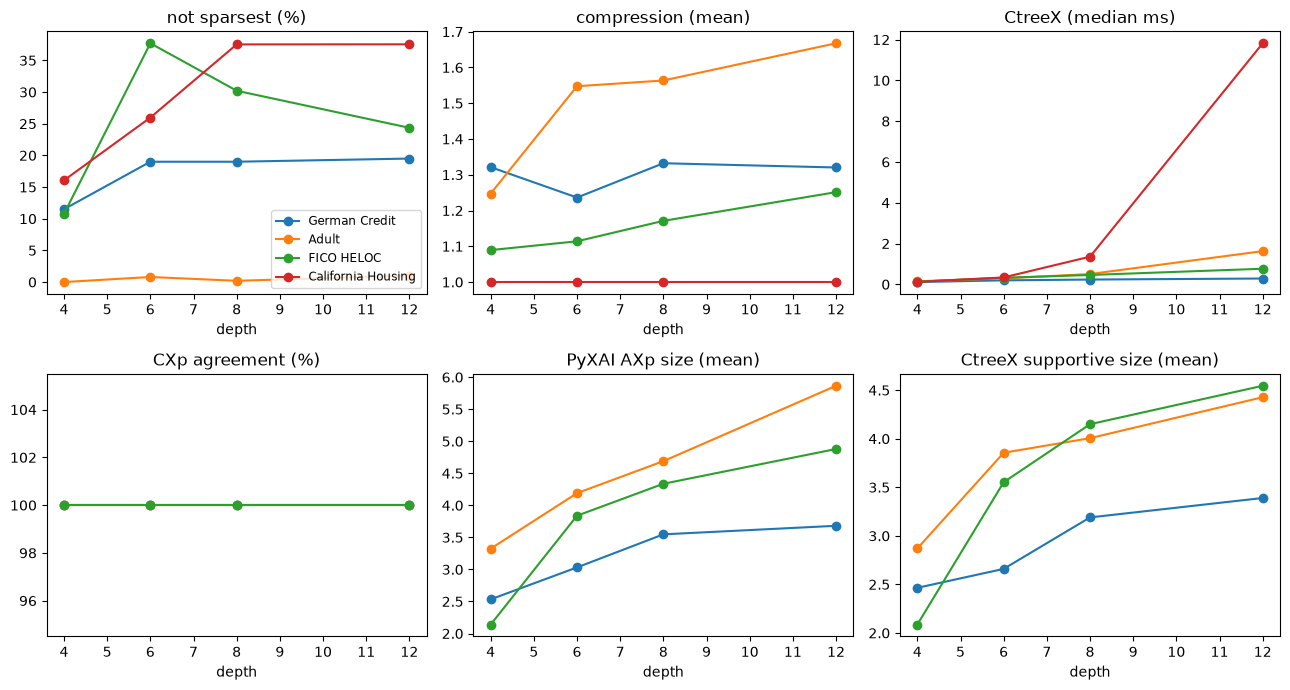

In [7]:
import matplotlib.pyplot as plt

panels = [(point_vs_ctreex, 'not_sparsest', 'not sparsest (%)'),
          (point_vs_ctreex, 'compression_mean', 'compression (mean)'),
          (point_vs_ctreex, 'ctreex_ms_median', 'CtreeX (median ms)'),
          (pyxai_vs_ctreex, 'cxp_agree', 'CXp agreement (%)'),
          (pyxai_vs_ctreex, 'pyxai_axp_mean', 'PyXAI AXp size (mean)'),
          (pyxai_vs_ctreex, 'ctreex_supportive_mean', 'CtreeX supportive size (mean)')]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (frame, column, label) in zip(axes.ravel(), panels):
    for dataset, rows in frame.groupby('dataset', sort=False):
        ax.plot(rows['depth'], rows[column], marker='o', label=dataset)
    ax.set_title(label)
    ax.set_xlabel('depth')
axes[0, 0].legend(fontsize='small')
fig.tight_layout()

## LaTeX tables (depth 12)

In [8]:
for name in ('point_vs_ctreex', 'pyxai_vs_ctreex'):
    with open(f'{ex.RESULTS}/{name}.tex') as f:
        print(f.read())

% generated by experiments/experiments.py -- do not edit
% counts: mean $\pm$ SD; times: median (IQR)
\begin{tabular}{lrrrrrr}
\toprule
 & \multicolumn{2}{c}{features changed} & not sparsest & compression & \multicolumn{2}{c}{time (ms)} \\
\cmidrule(lr){2-3}\cmidrule(lr){6-7}
dataset & point & CtreeX & (\%) & (leaves / CF) & point & CtreeX \\
\midrule
German Credit & $1.46 \pm 0.62$ & $1.25 \pm 0.43$ & 19.5 & $1.32 \pm 0.44$ & 0.10 (0.10--0.10) & 0.28 (0.27--0.39) \\
Adult & $1.02 \pm 0.15$ & $1.01 \pm 0.11$ & 1.0 & $1.67 \pm 0.31$ & 0.09 (0.09--0.11) & 1.63 (1.52--1.82) \\
FICO HELOC & $1.32 \pm 0.56$ & $1.04 \pm 0.20$ & 24.4 & $1.25 \pm 0.34$ & 0.06 (0.06--0.07) & 0.76 (0.69--1.07) \\
California Housing & $1.56 \pm 0.75$ & $1.09 \pm 0.33$ & 37.5 & $1.00 \pm 0.00$ & 0.08 (0.07--0.10) & 11.82 (5.72--20.02) \\
\bottomrule
\end{tabular}

% generated by experiments/experiments.py -- do not edit
% sizes: mean $\pm$ SD; times: median (IQR)
\begin{tabular}{lrrrrrr}
\toprule
 & CXp agree & fe